In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pickle
import sys
import pandas as pd
from scipy.spatial.distance import pdist
import json
sys.path.append("../../")
from helper_function import *
plt.rcParams['font.family'] = 'Arial'
plt.rcParams['font.size'] = 12

In [2]:
with open(f'../../FBAsolution/M9_sufficient_423_1_proteome_weakbg.pkl', 'rb') as pickle_file:
    data = pickle.load(pickle_file)
    all_met_flux4 = data['all_met_flux']
    del data

data = pd.read_excel("../../universal_model_reactions&subsystems.xlsx")

agora_to_kegg = json.load(open("agora_to_kegg_reaction.json"))

In [3]:
threshold = 1e-8

# all species flux lists
species_flux = all_met_flux4[0]


# -----------------------------
# build flux matrix
# -----------------------------

all_reactions = data["Reaction ID"].tolist()

flux_matrix = pd.DataFrame(
    0.0,
    index=all_reactions,
    columns=data.columns[2:]
)


for i, sp_flux in enumerate(species_flux):

    species = data.columns[2:][i]

    flux_dict = dict(sp_flux)

    flux_matrix[species] = (
        pd.Series(flux_dict)
        .reindex(all_reactions)
        .fillna(0)
    )


# -----------------------------
# convert flux -> presence
# -----------------------------

activate_matrix = (
    flux_matrix.abs()
    .gt(threshold)
    .astype(int)
)


# -----------------------------
# replace original data
# -----------------------------

activate_data = data.copy()

activate_data.iloc[:,2:] = (
    activate_matrix
    .loc[data["Reaction ID"]]
    .values
)

In [4]:
central_core_subsystems = [
    "Glycolysis/gluconeogenesis",
    "Pentose phosphate pathway",
    "Citric acid cycle",
    "Glyoxylate and dicarboxylate metabolism",
    "Pyruvate metabolism",
    "Oxidative phosphorylation",
]

In [5]:
ipath_edge_group = pd.read_csv('ipath_edge_group.csv')

groups = ipath_edge_group["reaction_ids"].apply(
    lambda x: x.split(";")
).tolist()

grouped_kegg = set(
    r
    for group in groups
    for r in group
)

all_kegg = set(agora_to_kegg.values())

groups.extend(
    [[r] for r in all_kegg - grouped_kegg]
)

all_kegg = set(agora_to_kegg.values())

groups = [
    group for group in groups
    if any(r in all_kegg for r in group)
]

In [6]:
all_species_presence = [] 
for col in data.columns[2:]: 
    species_presence = data[col].astype(bool)
    species = data.loc[species_presence,["Reaction ID", "Subsystem"]].copy() 
    species_reactions = [agora_to_kegg.get(reaction) for reaction in species["Reaction ID"].tolist()] 
    species_presence = np.array([any(r in species_reactions for r in group) for group in groups])

    all_species_presence.append(species_presence)

In [7]:
all_species_activate = [] 
for col in activate_data.columns[2:]: 
    species_activate = activate_data[col].astype(bool)
    species = activate_data.loc[species_activate,["Reaction ID", "Subsystem"]].copy() 
    species_reactions = [agora_to_kegg.get(reaction) for reaction in species["Reaction ID"].tolist()] 
    species_activate = np.array([any(r in species_reactions for r in group) for group in groups])

    all_species_activate.append(species_activate)

In [8]:
all_core_species_presence = []
core_data = data[
    data["Subsystem"].isin(central_core_subsystems)
]

for col in core_data.columns[2:]: 
    species_presence = core_data[col].astype(bool)
    species = core_data.loc[species_presence,["Reaction ID", "Subsystem"]].copy() 
    species_reactions = [agora_to_kegg.get(reaction) for reaction in species["Reaction ID"].tolist()] 
    species_presence = np.array([any(r in species_reactions for r in group) for group in groups])

    all_core_species_presence.append(species_presence)

In [9]:
all_core_species_activate = []
core_activate_data = activate_data[
    activate_data["Subsystem"].isin(central_core_subsystems)
]

for col in core_activate_data.columns[2:]: 
    species_activate = core_activate_data[col].astype(bool)
    species = core_activate_data.loc[species_activate,["Reaction ID", "Subsystem"]].copy() 
    species_reactions = [agora_to_kegg.get(reaction) for reaction in species["Reaction ID"].tolist()] 
    species_activate = np.array([any(r in species_reactions for r in group) for group in groups])

    all_core_species_activate.append(species_activate)

In [10]:
from scipy.spatial.distance import pdist

all_species_presence = np.array(all_species_presence)

jaccard_distance = pdist(
    all_species_presence,
    metric="jaccard"
)

all_core_species_presence = np.array(all_core_species_presence)
jaccard_distance_core = pdist(
    all_core_species_presence,
    metric="jaccard"
)

all_species_activate = np.array(all_species_activate)
jaccard_distance_activate = pdist(
    all_species_activate,
    metric="jaccard"
)

all_core_species_activate = np.array(all_core_species_activate)
jaccard_distance_core_activate = pdist(
    all_core_species_activate,
    metric="jaccard"
)

In [11]:
presence = (
    data.set_index("Reaction ID")[data.columns[2:]]
    .astype(bool)
)

activate_presence = (
    activate_data.set_index("Reaction ID")[activate_data.columns[2:]]
    .astype(bool)
)

subsystem = data.set_index("Reaction ID")["Subsystem"]


# ============================================================
# Jaccard dissimilarity
# ============================================================

all_jaccard = pdist(
    presence.T.to_numpy(),
    metric="jaccard",
)

# Central-core reactions
core_reaction_mask = subsystem.isin(
    central_core_subsystems
)

core_jaccard = pdist(
    presence.loc[core_reaction_mask]
    .T
    .to_numpy(),
    metric="jaccard",
)

all_activate_jaccard = pdist(
    activate_presence.T.to_numpy(),
    metric="jaccard",
)

core_activate_jaccard = pdist(
    activate_presence.loc[core_reaction_mask]
    .T
    .to_numpy(),
    metric="jaccard",
)

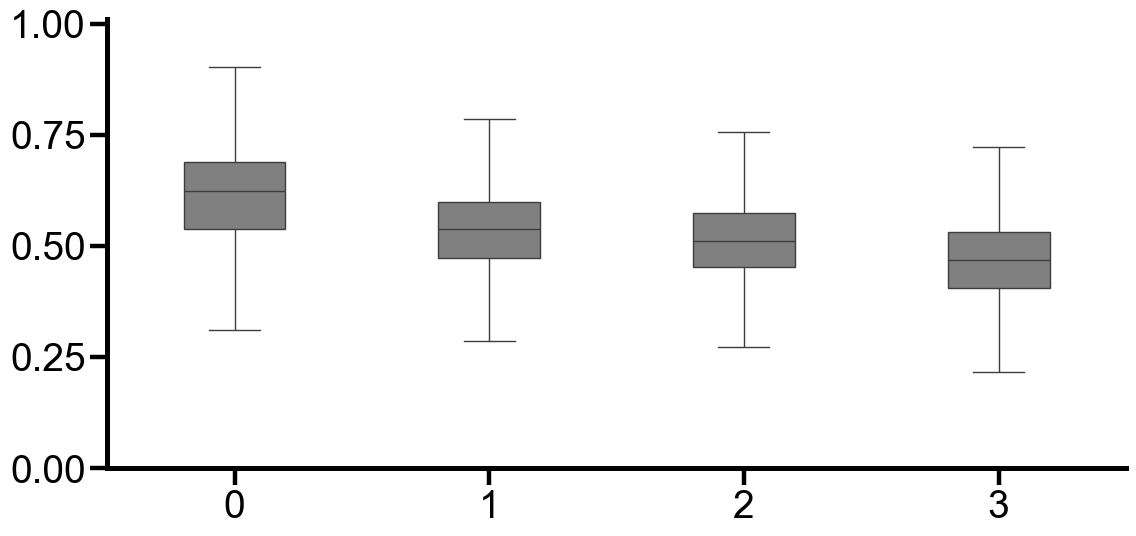

In [12]:
set_panel_style(scale=4)

plt.figure(figsize=(12, 6))

sns.boxplot(
    [all_jaccard, core_jaccard, jaccard_distance, jaccard_distance_core],
    color="gray",
    showfliers=False,
    width=0.4
)

plt.xticks([0, 1, 2, 3], ["0", "1", "2", "3"])
plt.ylim(0, 1.01)
plt.xlim(-0.5, 3.5)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

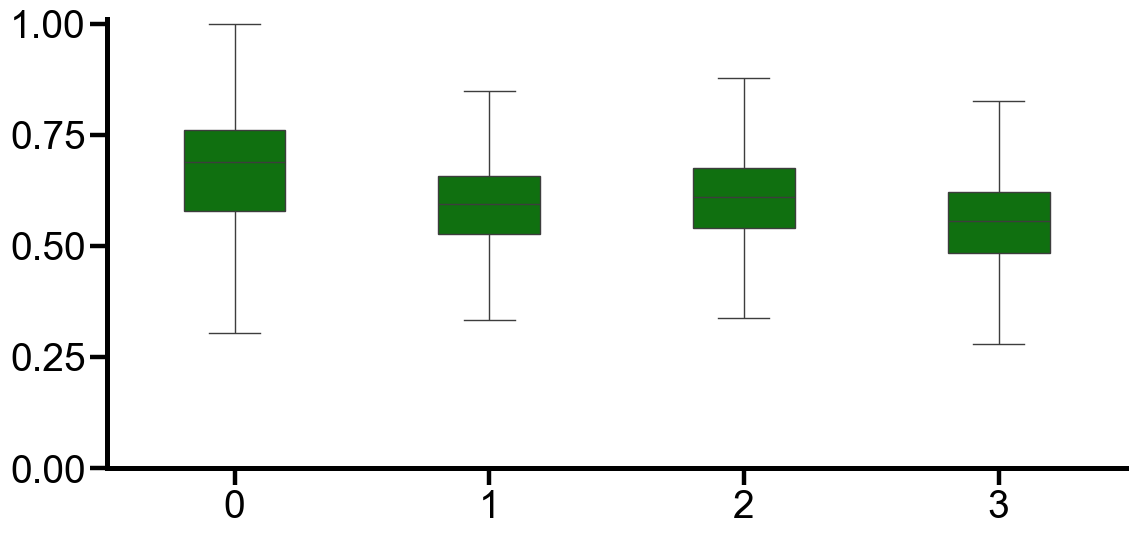

In [13]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    [all_activate_jaccard, core_activate_jaccard,
     jaccard_distance_activate, jaccard_distance_core_activate],
    color="green",
    showfliers=False,
    width=0.4
)

plt.xticks([0, 1, 2, 3], ["0", "1", "2", "3"])


plt.ylim(0, 1.01)
plt.xlim(-0.5, 3.5)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()